Importing libraries

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Importing dataset

In [4]:
raw_df = pd.read_excel("D:\Project\Customer-segmentation\data\online_retail_II.xlsx")
raw_df.head()

<>:1: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\P'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33736\935204090.py:1: SyntaxWarning: invalid escape sequence '\P'
  raw_df = pd.read_excel("D:\Project\Customer-segmentation\data\online_retail_II.xlsx")


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


#

Finding unique Country 

In [5]:
raw_df["Country"].unique()

<ArrowStringArray>
[      'United Kingdom',               'France',            'Australia',
          'Netherlands',              'Germany',               'Norway',
                 'EIRE',          'Switzerland',                'Spain',
               'Poland',             'Portugal',                'Italy',
              'Belgium',            'Lithuania',                'Japan',
              'Iceland',      'Channel Islands',              'Denmark',
               'Cyprus',               'Sweden',              'Austria',
               'Israel',              'Finland',              'Bahrain',
               'Greece',            'Hong Kong',            'Singapore',
              'Lebanon', 'United Arab Emirates',         'Saudi Arabia',
       'Czech Republic',               'Canada',          'Unspecified',
               'Brazil',                  'USA',   'European Community',
                'Malta',                  'RSA']
Length: 38, dtype: str

Dataset Information

In [6]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[us]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


Missing values in `description` and `customer id`

In [7]:
raw_df.isnull().sum()

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

Without a Customer ID, we cannot perform individual customer-level segmentation <br> We wil drop the missing customer id rows

In [8]:
raw_df = raw_df.dropna(subset=['Customer ID']).copy()

Removing cancelled invoices, negative quantities and prices



In [9]:
raw_df = raw_df[~raw_df['Invoice'].astype(str).str.startswith('C')]
raw_df = raw_df[(raw_df['Quantity'] > 0) & (raw_df['Price'] > 0)]

Removing Non-Product Administrative Stock Codes

In [10]:
# Remove administrative stock codes
non_product_codes = ['POST', 'D', 'M', 'PADS', 'DOT', 'CRUK', 'BANK CHARGES', 'CARRIAGE', 'AMAZONFEE']
raw_df = raw_df[~raw_df['StockCode'].astype(str).isin(non_product_codes)]

Convert Customer ID to integer

In [11]:
raw_df['Customer ID'] = raw_df['Customer ID'].astype(int)


Price * Quantity

In [12]:
raw_df['TotalSum'] = raw_df['Quantity'] * raw_df['Price']

In [13]:
raw_df['TotalSum'].describe()

count    396470.000000
mean         22.114542
std         308.847782
min           0.060000
25%           4.680000
50%          11.800000
75%          19.800000
max      168469.600000
Name: TotalSum, dtype: float64

<Axes: ylabel='TotalSum'>

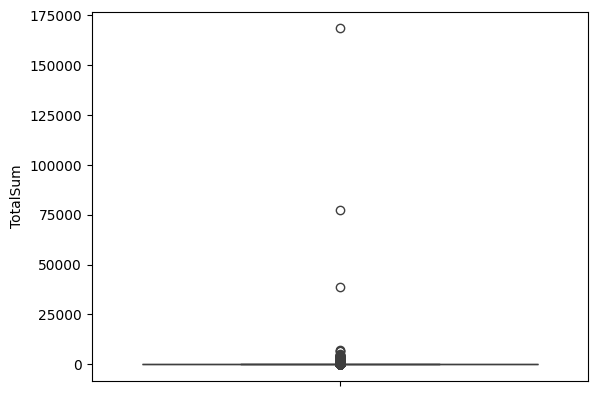

In [16]:
sns.boxplot(raw_df['TotalSum'])

Some Outliers in the `TotalSum` maybe wholesale orders, Will check customer rfm then decide.



In [26]:
raw_df.to_csv("D:\Project\Customer-segmentation\data\cleaned_OR2_data.csv", index=False)


<>:1: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\P'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33736\3288353105.py:1: SyntaxWarning: invalid escape sequence '\P'
  raw_df.to_csv("D:\Project\Customer-segmentation\data\cleaned_OR2_data.csv", index=False)
